# Streaming decision tree demo

Loads a CSV with our own `io.py`, splits it into chunks, trains a
`Pipeline(SimpleImputer -> StandardScaler -> DecisionTreeClassifier)` incrementally with
`.partial_fit()`, and logs and plots metrics over time with `visualise.py`.

The data (`demo/stream_data.csv`) has a **concept drift** halfway through (the labelling rule
changes), 5% label noise and 3% missing values, so we can see the tree recover after a retrain.

In [ ]:
import logging
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "demo" else Path.cwd()
sys.path.insert(0, str(ROOT))

from numcompute_stream.io import load_csv
from numcompute_stream.pipeline import Pipeline
from numcompute_stream.preprocessing import SimpleImputer, StandardScaler
from numcompute_stream.stream import StreamTrainer
from numcompute_stream.tree import DecisionTreeClassifier
from numcompute_stream import visualise as viz

logging.basicConfig(level=logging.INFO, format="%(message)s", force=True)

## 1. Load the CSV with `io.py` and split into chunks

In [ ]:
data = load_csv(ROOT / "demo" / "stream_data.csv", skip_header=1)   # empty cells -> NaN
X, y = data[:, :-1], data[:, -1].astype(int)
print("data:", data.shape, "| missing cells:", int(np.isnan(X).sum()), "| class balance:", np.bincount(y))

CHUNK = 100
chunks = [(X[i:i + CHUNK], y[i:i + CHUNK]) for i in range(0, len(X), CHUNK)]
print(len(chunks), "chunks of", CHUNK)

data: (6000, 5) | missing cells: 717 | class balance: [3151 2849]
60 chunks of 100


## 2. Train incrementally (test-then-train) with logging

In [ ]:
def make_pipe(buffer_size):
    return Pipeline([
        ("impute", SimpleImputer(strategy="mean")),
        ("scale", StandardScaler()),
        ("model", DecisionTreeClassifier(max_depth=5, buffer_size=buffer_size)),
    ])

trainer = StreamTrainer(make_pipe(500), rolling_window=500, log_every=10)
trainer.run(chunks)
h = trainer.history_
print("\nfinal cumulative accuracy: %.3f | retrains: %d | model memory: %d bytes"
      % (h["cumulative_accuracy"][-1], h["retrained"].sum(), h["memory_bytes"][-1]))

chunk    0 | rows     100 | acc   -   | rolling   -   | cum   -   | buffer    100 rows | mem    4.3 KB


chunk    4 | rows     500 | acc   -   | rolling   -   | cum   -   | retrain    6.0 ms | mem    2.8 KB


chunk    9 | rows    1000 | acc 0.890 | rolling 0.870 | cum 0.870 | retrain    4.9 ms | mem    2.4 KB


chunk   10 | rows    1100 | acc 0.870 | rolling 0.868 | cum 0.870 | buffer    100 rows | mem    6.3 KB


chunk   14 | rows    1500 | acc 0.860 | rolling 0.876 | cum 0.873 | retrain    5.4 ms | mem    2.8 KB


chunk   19 | rows    2000 | acc 0.880 | rolling 0.880 | cum 0.875 | retrain    5.1 ms | mem    2.8 KB


... (10 outputs left out)

chunk   54 | rows    5500 | acc 0.790 | rolling 0.874 | cum 0.853 | retrain    5.2 ms | mem    2.9 KB


chunk   59 | rows    6000 | acc 0.940 | rolling 0.910 | cum 0.858 | retrain    4.4 ms | mem    2.2 KB


done: 60 chunks, 6000 rows, 12 retrains, cumulative accuracy 0.858



final cumulative accuracy: 0.858 | retrains: 12 | model memory: 2277 bytes


## 3. Visualise metrics over time

Vertical hairlines mark retrains. The first chunks have no prediction (warm-up, NaN), and the dip after chunk 30 is the drift.

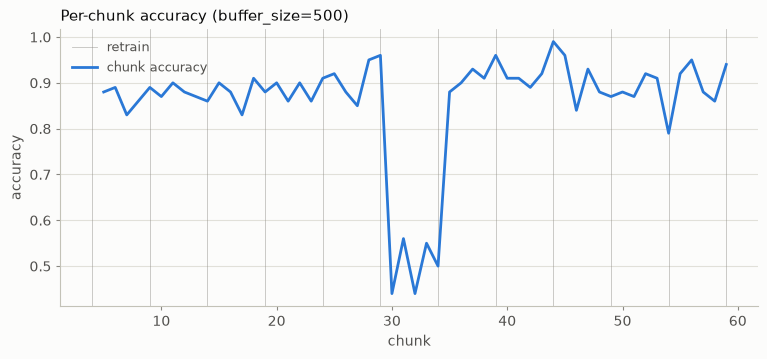

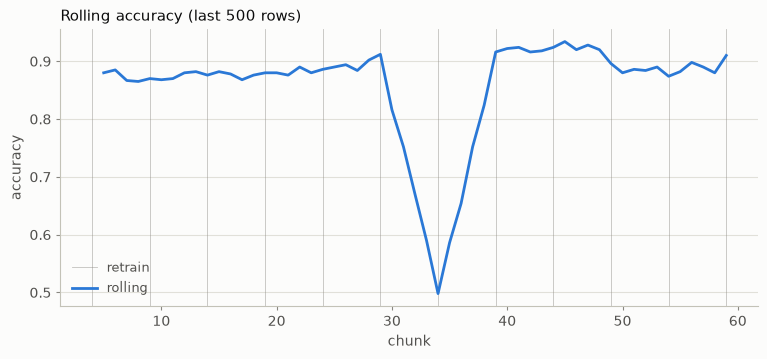

In [ ]:
viz.plot_metric_over_time(h["accuracy"], "Per-chunk accuracy (buffer_size=500)", "accuracy",
                          markers=h["retrained"].astype(bool), label="chunk accuracy")
viz.plot_metric_over_time(h["rolling_accuracy"], "Rolling accuracy (last 500 rows)", "accuracy",
                          markers=h["retrained"].astype(bool), label="rolling")
plt.show()

## 4. Compare `buffer_size` values

chunk    0 | rows     100 | acc   -   | rolling   -   | cum   -   | retrain    2.2 ms | mem    1.5 KB


chunk    1 | rows     200 | acc 0.900 | rolling 0.900 | cum 0.900 | retrain    2.1 ms | mem    1.6 KB


chunk    2 | rows     300 | acc 0.810 | rolling 0.855 | cum 0.855 | retrain    2.2 ms | mem    1.6 KB


chunk    3 | rows     400 | acc 0.870 | rolling 0.860 | cum 0.860 | retrain    1.5 ms | mem    1.3 KB


chunk    4 | rows     500 | acc 0.840 | rolling 0.855 | cum 0.855 | retrain    2.4 ms | mem    1.8 KB


chunk    5 | rows     600 | acc 0.830 | rolling 0.850 | cum 0.850 | retrain    2.0 ms | mem    1.6 KB


... (71 outputs left out)

chunk   39 | rows    4000 | acc 0.480 | rolling 0.512 | cum 0.711 | retrain   13.5 ms | mem    3.1 KB


chunk   59 | rows    6000 | acc 0.860 | rolling 0.868 | cum 0.795 | retrain   12.9 ms | mem    2.6 KB


done: 60 chunks, 6000 rows, 3 retrains, cumulative accuracy 0.795


buffer_size=  100  cumulative acc=0.851  retrains= 60  total retrain time=0.112s
buffer_size=  500  cumulative acc=0.858  retrains= 12  total retrain time=0.058s
buffer_size= 2000  cumulative acc=0.795  retrains=  3  total retrain time=0.041s


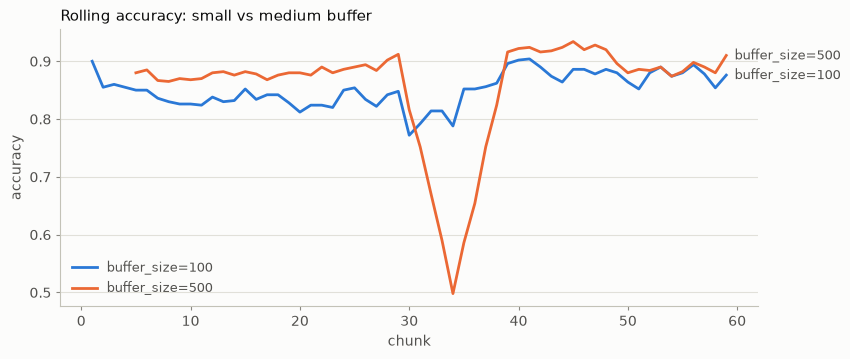

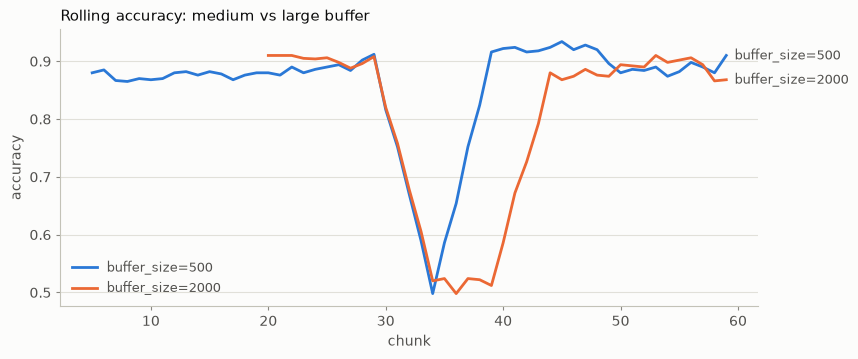

In [ ]:
runs = {}
for b in (100, 500, 2000):
    runs[b] = StreamTrainer(make_pipe(b), rolling_window=500, log_every=10**6).run(chunks).history_
    print(f"buffer_size={b:5d}  cumulative acc={runs[b]['cumulative_accuracy'][-1]:.3f}  "
          f"retrains={int(runs[b]['retrained'].sum()):3d}  "
          f"total retrain time={runs[b]['retrain_time'].sum():.3f}s")

viz.compare_models(runs[100]["rolling_accuracy"], runs[500]["rolling_accuracy"],
                   labels=("buffer_size=100", "buffer_size=500"),
                   title="Rolling accuracy: small vs medium buffer", ylabel="accuracy")
viz.compare_models(runs[500]["rolling_accuracy"], runs[2000]["rolling_accuracy"],
                   labels=("buffer_size=500", "buffer_size=2000"),
                   title="Rolling accuracy: medium vs large buffer", ylabel="accuracy")
plt.show()

## 5. Predictions vs ground truth on the latest chunk

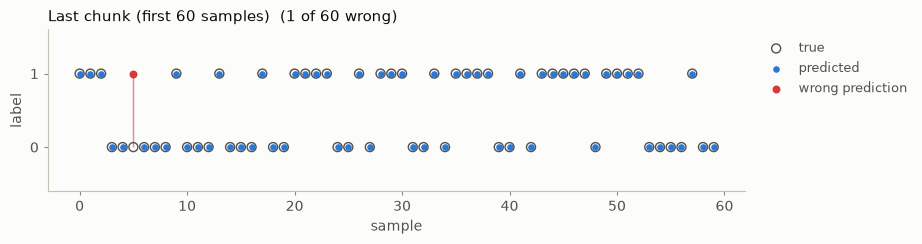

In [ ]:
model = trainer.model
Xl, yl = chunks[-1]
viz.plot_predictions_vs_ground_truth(yl[:60], model.predict(Xl)[:60],
                                     title="Last chunk (first 60 samples)")
plt.show()

## 6. Log table

The full per-chunk history can also be exported with `trainer.to_csv(...)`.

In [ ]:
print("chunk  seen  acc    cum    rolling  retrained  fit_time(s)  buffer")
for i in list(range(0, 60, 6)):
    print(f"{h['chunk'][i]:5d} {h['seen'][i]:5d} {h['accuracy'][i]:.3f}  {h['cumulative_accuracy'][i]:.3f}  "
          f"{h['rolling_accuracy'][i]:.3f}    {int(h['retrained'][i])}          {h['fit_time'][i]:.4f}      {h['buffer_count'][i]}")

chunk  seen  acc    cum    rolling  retrained  fit_time(s)  buffer
    0   100 nan  nan  nan    0          0.0004      100
    6   700 0.890  0.885  0.885    0          0.0002      200
   12  1300 0.880  0.875  0.880    0          0.0002      300
   18  1900 0.910  0.875  0.876    0          0.0002      400
   24  2500 0.910  0.878  0.886    1          0.0054      0
   30  3100 0.440  0.868  0.816    0          0.0002      100
   36  3700 0.900  0.825  0.654    0          0.0002      200
   42  4300 0.890  0.839  0.916    0          0.0002      300
   48  4900 0.880  0.850  0.920    0          0.0002      400
   54  5500 0.790  0.853  0.874    1          0.0052      0
